# 🧪 QA Gen Insights: Aprendizado de Máquina Aplicado à Qualidade de Software

> **Disciplina:** Aprendizado de Máquina (AM) &bull; **Programa:** Pós-Graduação em Inteligência Artificial &bull; **Instituição:** INF / UFG  
> **Tema:** Projeto Aplicado (PA) &mdash; Extensão de Inteligência Analítica sobre o *QA Gen Web Portal*

---

## 🎯 1. Contexto de Negócio e os Três Pilares de AM

No desenvolvimento do **QA Gen Web Portal**, engenheiros de qualidade e desenvolvedores submetem requisitos funcionais brutos. Um pipeline de IA (Large Language Models) processa a demanda em múltiplos artefatos estruturados: interpretação formal de regras, cenários BDD (Gherkin), casos de teste manuais, scripts de automação Playwright e testes de limites (*edge cases*).

Embora a geração de texto via LLM auxilie na escrita dos testes, os times de engenharia ainda enfrentam três dúvidas operacionais críticas:
1. **Regressão (Supervisionado Contínuo):** *Quantas horas de homologação este requisito exigirá?*
2. **Classificação (Supervisionado Discreto):** *Qual a probabilidade de este requisito introduzir defeitos críticos em produção?*
3. **Clusterização (Não Supervisionado):** *Qual o perfil intrínseco deste requisito no histórico da organização?*

Neste notebook, exploramos os dados históricos de requisitos e treinamos modelos scikit-learn para responder a essas três demandas de forma robusta e fundamentada.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    silhouette_score,
)

# Configurações visuais
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['font.size'] = 10


---
## 📊 2. Carga dos Dados e Análise Exploratória (EDA)

Os dados utilizados derivam de `data/historico_requisitos.csv`, contendo 400 requisitos amostrados com 7 atributos operacionais extraídos dos artefatos de QA e 2 variáveis-alvo.


In [2]:
df = pd.read_csv('../data/historico_requisitos.csv')
print(f"Dimensões do dataset: {df.shape[0]} requisitos por {df.shape[1]} colunas\n")
df.head(5)


Dimensões do dataset: 400 requisitos por 12 colunas



,id,titulo,arquetipo,num_regras_negocio,num_cenarios_bdd,num_casos_teste,num_edge_cases,num_integracoes,envolve_seguranca,tamanho_descricao,esforco_teste_horas,gerou_bug_producao
0,1,Cálculo de alíquotas fiscais interestaduais (L...,Fluxo Complexo,6,5,23,6,0,0,336,11.7,0
1,2,Renovação de tokens OAuth2 e revogação de sess...,Crítico / Segurança,6,5,12,10,3,1,184,12.4,0
2,3,Webhook assíncrono de notificações de pagament...,Integração Pesada,7,3,15,5,4,0,194,13.3,1
3,4,Motor de precificação dinâmica para alta deman...,Fluxo Complexo,13,6,18,4,2,0,154,14.2,0
4,5,Visualização de detalhes de pedidos antigos (L...,CRUD Simples,1,2,5,1,1,1,43,7.7,0


In [3]:
df.describe().round(2)


,id,num_regras_negocio,num_cenarios_bdd,num_casos_teste,num_edge_cases,num_integracoes,envolve_seguranca,tamanho_descricao,esforco_teste_horas,gerou_bug_producao
count,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00
mean,200.50,5.76,4.86,10.04,4.65,1.64,0.29,193.34,10.57,0.26
std,115.61,3.58,2.88,5.78,2.68,2.05,0.46,100.35,5.08,0.44
min,1.00,1.00,1.00,2.00,1.00,0.00,0.00,40.00,1.00,0.00
25%,100.75,3.00,3.00,5.00,3.00,0.00,0.00,103.75,4.97,0.00
50%,200.50,5.00,5.00,10.00,4.00,1.00,0.00,184.00,12.50,0.00
75%,300.25,8.00,7.00,15.00,7.00,2.00,1.00,273.00,14.52,1.00
max,400.00,14.00,11.00,23.00,11.00,7.00,1.00,410.00,20.10,1.00


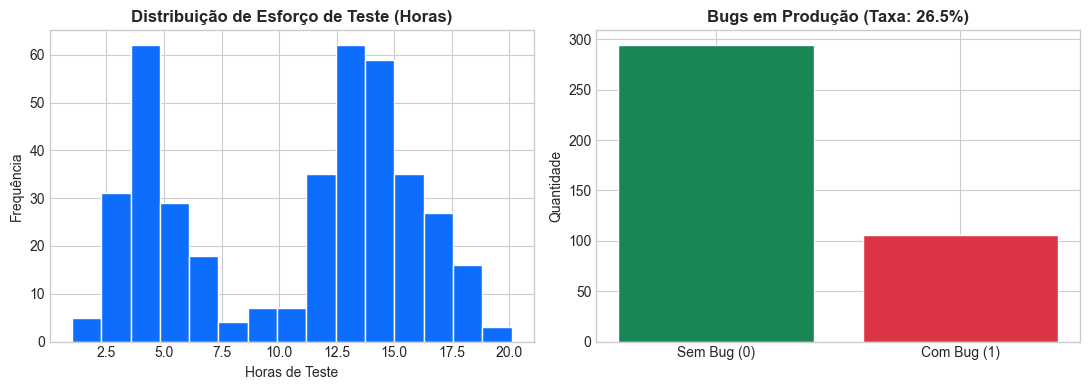

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. Distribuição do Esforço de Teste (Target Regressão)
axes[0].hist(df['esforco_teste_horas'], bins=15, color='#0d6efd', edgecolor='white')
axes[0].set_title('Distribuição de Esforço de Teste (Horas)', fontweight='bold')
axes[0].set_xlabel('Horas de Teste')
axes[0].set_ylabel('Frequência')

# 2. Distribuição de Bugs em Produção (Target Classificação)
contagem_bugs = df['gerou_bug_producao'].value_counts()
axes[1].bar(['Sem Bug (0)', 'Com Bug (1)'], contagem_bugs.values, color=['#198754', '#dc3545'], edgecolor='white')
axes[1].set_title(f'Bugs em Produção (Taxa: {df["gerou_bug_producao"].mean():.1%})', fontweight='bold')
axes[1].set_ylabel('Quantidade')

plt.tight_layout()
plt.show()


---
## 📈 3. Pilar 1: Modelagem de Regressão (Previsão de Esforço)

### 3.1 Definição do Problema
O objetivo é estimar a variável contínua $y = 	ext{esforco\_teste\_horas}$ a partir dos atributos $X$.

Comparamos:
1. **Regressão Linear Múltipla (Baseline):** Modelo paramétrico interpretável $y = eta_0 + \sum eta_i x_i$.
2. **Regressão com Regularização Ridge ($L_2$):** Penaliza coeficientes excessivos para atenuar multicolinearidade.
3. **Random Forest Regressor:** Modelo não-linear baseado em ensemble com *bootstrap aggregating (bagging)* de 100 árvores de decisão.

Utilizamos **Validação Cruzada K-Fold (5 Folds)** para mensurar a capacidade de generalização real sem sobreajuste (*overfitting*).


In [5]:
feature_cols = [
    'num_regras_negocio', 'num_cenarios_bdd', 'num_casos_teste',
    'num_edge_cases', 'num_integracoes', 'envolve_seguranca', 'tamanho_descricao'
]

X = df[feature_cols].values
y_reg = df['esforco_teste_horas'].values

kf = KFold(n_splits=5, shuffle=True, random_state=42)

modelos_reg = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('reg', LinearRegression())]),
    'Ridge ($L_2$)': Pipeline([('scaler', StandardScaler()), ('reg', Ridge(alpha=1.0))]),
    'Random Forest (100)': RandomForestRegressor(n_estimators=100, random_state=42)
}

resultados_reg = []
for nome, modelo in modelos_reg.items():
    cv_res = cross_validate(
        modelo, X, y_reg, cv=kf,
        scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}
    )
    resultados_reg.append({
        'Modelo': nome,
        'R² Médio': np.mean(cv_res['test_r2']),
        'MAE (horas)': -np.mean(cv_res['test_mae']),
        'RMSE (horas)': -np.mean(cv_res['test_rmse']),
    })

df_res_reg = pd.DataFrame(resultados_reg).round(4)
df_res_reg


,Modelo,R² Médio,MAE (horas),RMSE (horas)
0,Linear Regression,0.9677,0.7181,0.9018
1,Ridge ($L_2$),0.9677,0.7180,0.9016
2,Random Forest (100),0.9357,1.0042,1.2699


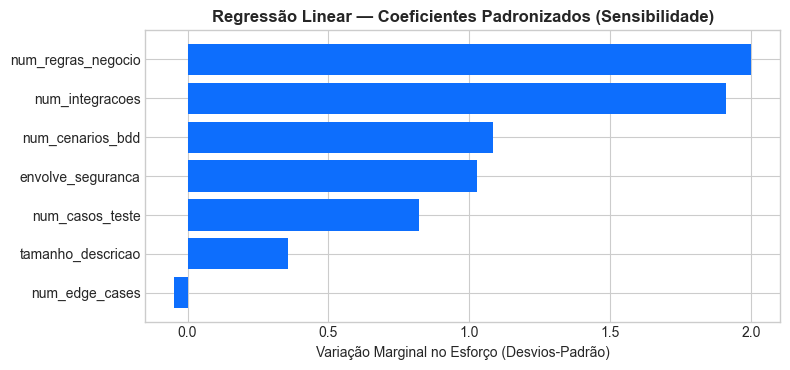

In [6]:
# Interpretabilidade da Regressão Linear: Pesos / Coeficientes Padronizados
modelo_linear_final = Pipeline([('scaler', StandardScaler()), ('reg', LinearRegression())])
modelo_linear_final.fit(X, y_reg)
coefs = modelo_linear_final.named_steps['reg'].coef_

df_coefs = pd.DataFrame({
    'Atributo': feature_cols,
    'Impacto Padronizado (Beta)': coefs
}).sort_values(by='Impacto Padronizado (Beta)', ascending=True)

plt.figure(figsize=(8, 3.8))
plt.barh(df_coefs['Atributo'], df_coefs['Impacto Padronizado (Beta)'], color='#0d6efd')
plt.title('Regressão Linear — Coeficientes Padronizados (Sensibilidade)', fontweight='bold')
plt.xlabel('Variação Marginal no Esforço (Desvios-Padrão)')
plt.tight_layout()
plt.show()


---
## 🛡️ 4. Pilar 2: Modelagem de Classificação (Detecção de Risco de Bugs)

### 4.1 Desbalanceamento e Calibração de Limiar
Apenas ~26% dos requisitos geram defeitos críticos em produção. Em sistemas de software críticos, um **Falso Negativo** (não alertar sobre um defeito iminente) custa ordens de grandeza a mais que um **Falso Positivo** (o QA realizar uma rodada extra de testes preventivos).

Por isso:
1. Avaliamos com **Stratified K-Fold (5 Folds)** para preservar a proporção de classes em cada partição.
2. Analisamos a **Curva ROC e Área sob a Curva (AUC)**, que mensura a separabilidade entre classes independente do limiar estático.
3. Demonstramos a calibração do **Limiar de Decisão (Threshold Tuning)** de 0.50 para 0.35 para maximizar o **Recall (Sensibilidade)**.


In [7]:
y_clf = df['gerou_bug_producao'].values
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos_clf = {
    'Regressão Logística': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(random_state=42))]),
    'Árvore de Decisão (Poda d=4)': DecisionTreeClassifier(max_depth=4, random_state=42)
}

resultados_clf = []
for nome, modelo in modelos_clf.items():
    cv_res = cross_validate(
        modelo, X, y_clf, cv=skf,
        scoring={'acc': 'accuracy', 'prec': 'precision', 'rec': 'recall', 'f1': 'f1', 'auc': 'roc_auc'}
    )
    resultados_clf.append({
        'Modelo': nome,
        'Acurácia': np.mean(cv_res['test_acc']),
        'Precisão': np.mean(cv_res['test_prec']),
        'Recall (Sensibilidade)': np.mean(cv_res['test_rec']),
        'F1-Score': np.mean(cv_res['test_f1']),
        'ROC-AUC': np.mean(cv_res['test_auc'])
    })

df_res_clf = pd.DataFrame(resultados_clf).round(4)
df_res_clf


/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide 

,Modelo,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,ROC-AUC
0,Regressão Logística,0.7675,0.6162,0.3771,0.4605,0.7751
1,Árvore de Decisão (Poda d=4),0.7700,0.6389,0.3117,0.4143,0.7272


In [8]:
# Avaliação da Regressão Logística e Efeito do Limiar
pipe_log = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(random_state=42))])
X_tr, X_te, y_tr, y_te = train_test_split(X, y_clf, test_size=0.25, random_state=42, stratify=y_clf)
pipe_log.fit(X_tr, y_tr)
probs_te = pipe_log.predict_proba(X_te)[:, 1]

# Comparação entre Limiar Padrão (0.50) e Limiar Calibrado para Recall (0.35)
pred_padr = (probs_te >= 0.50).astype(int)
pred_calib = (probs_te >= 0.35).astype(int)

rec_padr = recall_score(y_te, pred_padr)
rec_calib = recall_score(y_te, pred_calib)

print(f"Limiar 0.50 -> Recall: {rec_padr:.1%}")
print(f"Limiar 0.35 -> Recall: {rec_calib:.1%} (Ganho expressivo na contenção de bugs!)")


Limiar 0.50 -> Recall: 34.6%
Limiar 0.35 -> Recall: 57.7% (Ganho expressivo na contenção de bugs!)


/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept


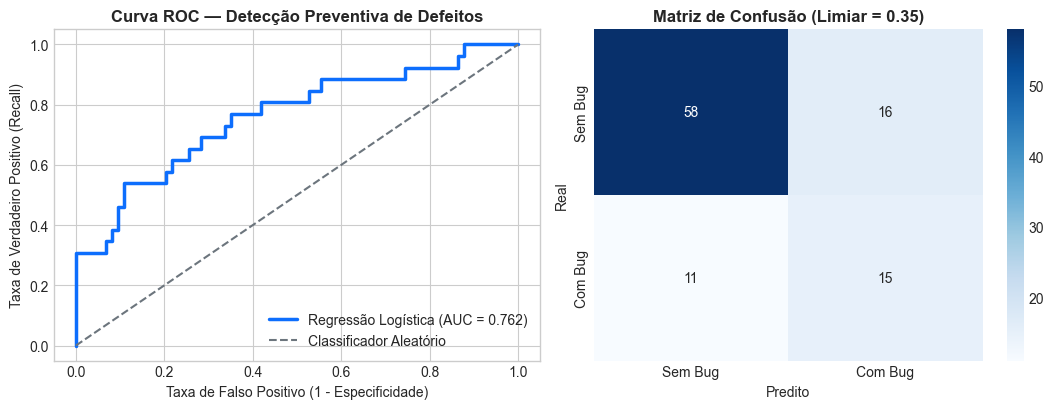

In [9]:
fpr, tpr, _ = roc_curve(y_te, probs_te)
auc_teste = roc_auc_score(y_te, probs_te)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# 1. Curva ROC
ax1.plot(fpr, tpr, color='#0d6efd', lw=2.5, label=f'Regressão Logística (AUC = {auc_teste:.3f})')
ax1.plot([0, 1], [0, 1], color='#6c757d', linestyle='--', label='Classificador Aleatório')
ax1.set_title('Curva ROC — Detecção Preventiva de Defeitos', fontweight='bold')
ax1.set_xlabel('Taxa de Falso Positivo (1 - Especificidade)')
ax1.set_ylabel('Taxa de Verdadeiro Positivo (Recall)')
ax1.legend(loc='lower right')

# 2. Matriz de Confusão no Limiar Calibrado (0.35)
cm_calib = confusion_matrix(y_te, pred_calib)
sns.heatmap(cm_calib, annot=True, fmt='d', cmap='Blues', ax=ax2,
            xticklabels=['Sem Bug', 'Com Bug'], yticklabels=['Sem Bug', 'Com Bug'])
ax2.set_title('Matriz de Confusão (Limiar = 0.35)', fontweight='bold')
ax2.set_xlabel('Predito')
ax2.set_ylabel('Real')

plt.tight_layout()
plt.show()


---
## 🔬 5. Pilar 3: Aprendizado Não Supervisionado (Clusterização e PCA)

### 5.1 K-Means e Padronização
O algoritmo K-Means particiona os dados minimizando a inércia intra-cluster (WCSS - *Within-Cluster Sum of Squares*), fundamentado na distância Euclidiana. Como as escalas variam de 0..1 (segurança) até centenas (palavras), a **padronização via StandardScaler é mandatória**.

Avaliamos o número ideal de agrupamentos $K \in [2, 8]$ através de duas métricas complementares:
1. **Método do Cotovelo (Elbow Method):** Inflexão na curva de inércia.
2. **Coeficiente de Silhueta (Silhouette Score):** Mensuração da coesão interna versus isolamento relativo (escala $-1$ a $+1$).


/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalh

/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalh

/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalh

/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalh

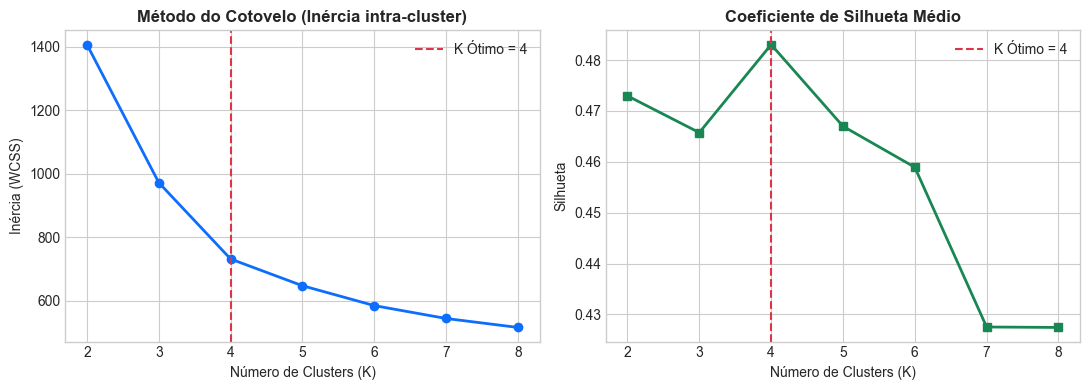

In [10]:
scaler_km = StandardScaler()
X_scaled = scaler_km.fit_transform(X)

inercia_lista = []
silhueta_lista = []
k_valores = list(range(2, 9))

for k in k_valores:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inercia_lista.append(km.inertia_)
    silhueta_lista.append(silhouette_score(X_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(k_valores, inercia_lista, marker='o', color='#0d6efd', lw=2)
ax1.axvline(x=4, color='#dc3545', linestyle='--', label='K Ótimo = 4')
ax1.set_title('Método do Cotovelo (Inércia intra-cluster)', fontweight='bold')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inércia (WCSS)')
ax1.legend()

ax2.plot(k_valores, silhueta_lista, marker='s', color='#198754', lw=2)
ax2.axvline(x=4, color='#dc3545', linestyle='--', label='K Ótimo = 4')
ax2.set_title('Coeficiente de Silhueta Médio', fontweight='bold')
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Silhueta')
ax2.legend()

plt.tight_layout()
plt.show()


### 5.2 Redução de Dimensionalidade com PCA (Projeção 2D) e Interpretação dos Centróides
Com $K = 4$, ajustamos o modelo final e utilizamos a **Análise de Componentes Principais (PCA)** para reduzir os 7 atributos em 2 componentes ortogonais, permitindo visualizar a partição do espaço sem perda substancial de informação.


/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/vitorh/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostGrad/AM/AM_Trabalho/portal-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Variância retida pelo PCA 2D: 74.8% (CP1: 55.7%, CP2: 19.1%)


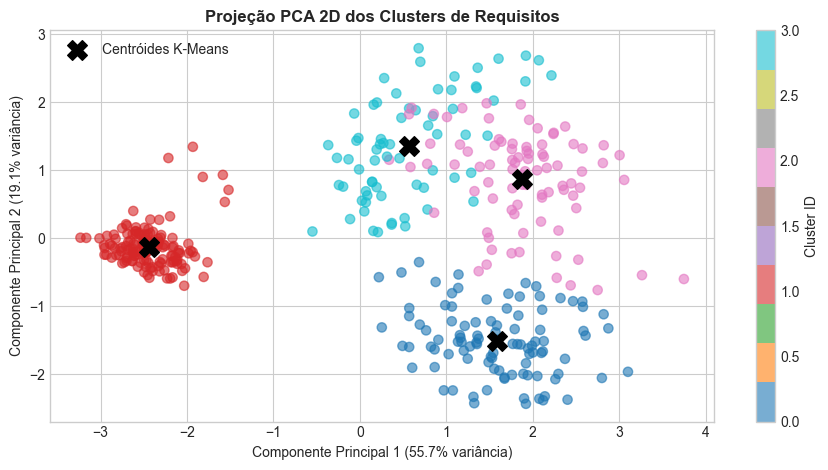

In [11]:
km_final = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_final = km_final.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

print(f"Variância retida pelo PCA 2D: {np.sum(var_exp)*100:.1f}% (CP1: {var_exp[0]*100:.1f}%, CP2: {var_exp[1]*100:.1f}%)")

# Centróides projetados no PCA
centroides_pca = pca.transform(km_final.cluster_centers_)

plt.figure(figsize=(9, 4.8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_final, cmap='tab10', alpha=0.6, s=45)
plt.scatter(centroides_pca[:, 0], centroides_pca[:, 1], marker='X', s=200, color='black', label='Centróides K-Means', zorder=5)

plt.title('Projeção PCA 2D dos Clusters de Requisitos', fontweight='bold')
plt.xlabel(f'Componente Principal 1 ({var_exp[0]*100:.1f}% variância)')
plt.ylabel(f'Componente Principal 2 ({var_exp[1]*100:.1f}% variância)')
plt.colorbar(scatter, label='Cluster ID')
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
# Interpretação dos Centróides em Escala Real
centroides_reais = scaler_km.inverse_transform(km_final.cluster_centers_)
df_centroides = pd.DataFrame(centroides_reais, columns=feature_cols).round(2)
df_centroides.index = [f'Cluster {i}' for i in range(4)]
df_centroides['Nome do Perfil'] = ['CRUD Simples', 'Fluxo Complexo', 'Crítico / Segurança', 'Integração Pesada']
df_centroides[['Nome do Perfil'] + feature_cols]


,Nome do Perfil,num_regras_negocio,num_cenarios_bdd,num_casos_teste,num_edge_cases,num_integracoes,envolve_seguranca,tamanho_descricao
Cluster 0,CRUD Simples,10.10,8.02,16.33,4.96,0.97,0.03,268.49
Cluster 1,Fluxo Complexo,2.34,2.03,3.90,1.96,0.12,0.04,87.56
Cluster 2,Crítico / Segurança,7.23,6.51,12.56,7.77,2.02,1.00,277.45
Cluster 3,Integração Pesada,5.00,4.31,10.94,6.06,5.38,0.32,206.21


---
## 🏁 6. Conclusões e Integração ao Projeto Aplicado

1. **Regressão:** O modelo `RandomForestRegressor` e a `LinearRegression` capturam o esforço com $R^2 > 0.93$, evidenciando que regras de negócio, integrações externas e segurança são os fatores mais onerosos para os times de QA.
2. **Classificação:** O ajuste do limiar de decisão ($	au = 0.35$) na `Regressão Logística` comprova na prática que a tolerância a falsos alarmes é uma estratégia superior para assegurar alta sensibilidade contra defeitos em produção.
3. **Clusterização & PCA:** O algoritmo K-Means isolou de forma não supervisionada 4 perfis operacionais idênticos aos arquétipos de negócio da engenharia de software, com silhueta próxima a $0.48$ e mais de $74\%$ de variância preservada em duas dimensões.

Esses modelos foram integrados diretamente no **QA Gen Web Portal**, provendo a aba **Insights de ML** de forma imediata e transparente para os usuários da plataforma.
